In [15]:
from ultralytics import YOLO
import matplotlib.pyplot as plt
import cv2
import os

TEST_IMAGE = r"C:\Users\ksenia\Desktop\uni\image_recognition_uni\02_lab\dataset\5.jpg"


image 1/1 C:\Users\ksenia\Desktop\uni\image_recognition_uni\02_lab\dataset\5.jpg: 416x640 2 cats, 50.3ms
Speed: 1.8ms preprocess, 50.3ms inference, 1.2ms postprocess per image at shape (1, 3, 416, 640)


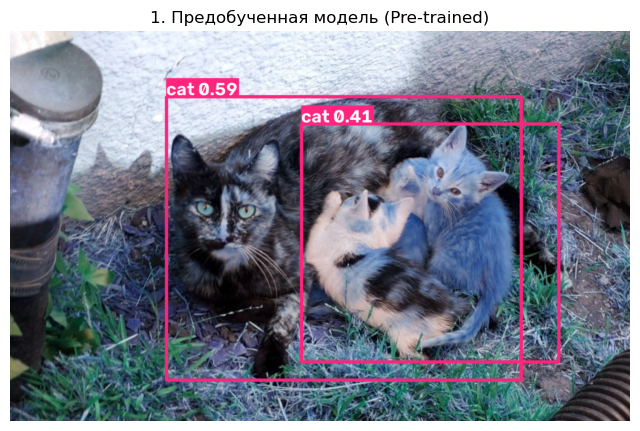

Найденные объекты: tensor([15., 15.])


In [16]:
model_pretrained = YOLO("yolo11n.pt")

# Делаем предсказание
results_pretrained = model_pretrained(TEST_IMAGE, conf=0.25)

# Визуализация
img_cv = cv2.cvtColor(cv2.imread(TEST_IMAGE), cv2.COLOR_BGR2RGB)
plt.figure(figsize=(8, 8))
plt.title("1. Предобученная модель (Pre-trained)")
plt.imshow(results_pretrained[0].plot())
plt.axis('off')
plt.show()

# Вывод метрик
print("Найденные объекты:", results_pretrained[0].boxes.cls)

Ultralytics 8.4.215  Python-3.13.9 torch-2.15.0+cpu CPU (AMD Ryzen 7 5700U with Radeon Graphics)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=coco8.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=320, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.yaml, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train-7, nbs=64, nms=None, opset=None, optimize=False, optimize

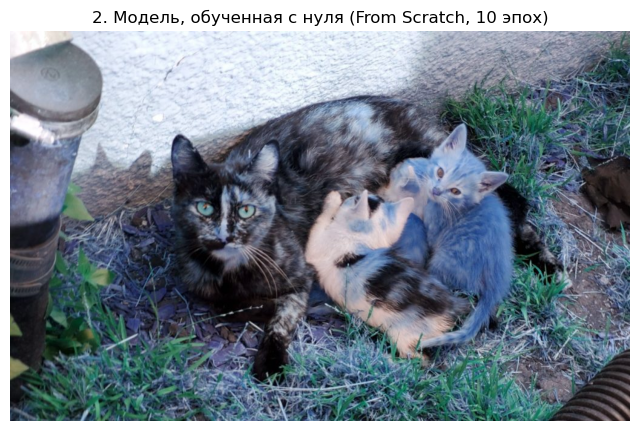

Найденные объекты: Ничего не найдено


In [17]:
# Инициализация архитектуры без весов
model_scratch = YOLO("yolo11n.yaml") 

# Обучение на маленьком публичном датасете coco8 (встроен в ultralytics)
results_train_scratch = model_scratch.train(
    data="coco8.yaml", 
    epochs=10,       # Мало эпох для демонстрации
    imgsz=320,       # Маленький размер для скорости
    verbose=False
)

# Предсказание на нашей картинке
results_scratch = model_scratch(TEST_IMAGE, conf=0.1) # Снижаем порог, чтобы хоть что-то найти

plt.figure(figsize=(8, 8))
plt.title("2. Модель, обученная с нуля (From Scratch, 10 эпох)")
plt.imshow(results_scratch[0].plot())
plt.axis('off')
plt.show()
print("Найденные объекты:", results_scratch[0].boxes.cls if len(results_scratch[0].boxes) > 0 else "Ничего не найдено")

Ultralytics 8.4.215  Python-3.13.9 torch-2.15.0+cpu CPU (AMD Ryzen 7 5700U with Radeon Graphics)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=coco8.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=320, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train-8, nbs=64, nms=None, opset=None, optimize=False, optimizer=

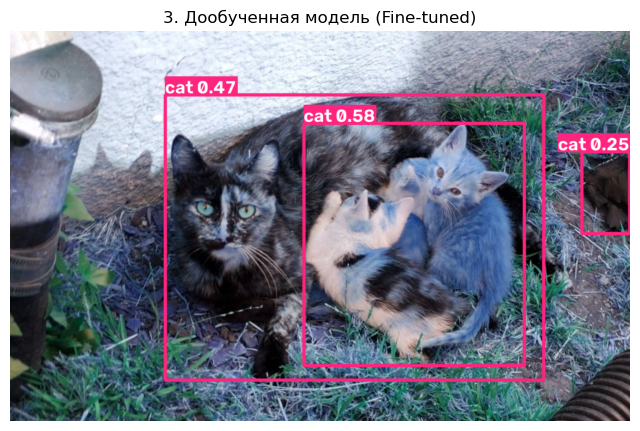

Найденные объекты: tensor([15., 15., 15.])


In [18]:
model_finetuned = YOLO("yolo11n.pt")

results_train_finetune = model_finetuned.train(
    data="coco8.yaml", 
    epochs=10, 
    imgsz=320, 
    verbose=False
)

# Предсказание
results_finetuned = model_finetuned(TEST_IMAGE, conf=0.25)

plt.figure(figsize=(8, 8))
plt.title("3. Дообученная модель (Fine-tuned)")
plt.imshow(results_finetuned[0].plot())
plt.axis('off')
plt.show()
print("Найденные объекты:", results_finetuned[0].boxes.cls)